# 3. Scenario analysis (what-if)

**Component 3, Electricity Demand Forecasting with Scenario Analysis** | Dewmini D.M.D.P (IT22630216)

**The idea.** A scenario changes some inputs (for example, temperature +8 °C) and asks the **same trained model** again.
The difference between the two predictions is the scenario's effect on demand.

**Caveat.** Scenario results show what the model learned from the training data: direction and rough size, not proven real-world causes.

**Data:** `notebooks/load_forecasting_dataset_corrected.csv` (189,888 fifteen-minute records, 2020 to 2025, 13 input features).

**Output written:** `backend/outputs/scenario_results.json` (served by `GET /api/scenarios`).

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent
MODELS, OUTPUTS = ROOT / 'backend' / 'saved_models', ROOT / 'backend' / 'outputs'
plt.rcParams['figure.dpi'] = 100

meta = json.load(open(MODELS / 'model_metadata.json'))
FEATURES = meta['feature_names']
model = joblib.load(MODELS / 'forecast_model.pkl')
df = pd.read_csv(ROOT / 'notebooks' / 'load_forecasting_dataset_corrected.csv')
print('Model:', meta['model_type'], '| features:', len(FEATURES))

Model: GradientBoostingRegressor | features: 13


## Step 1: Define the scenarios
Each scenario is a function that edits a copy of the inputs.

| Scenario | Change |
|---|---|
| Heat wave | temperature +8 °C, humidity -15 points |
| Cold spell | temperature -10 °C (not below 0), humidity +20 points (not above 100) |
| Price shock | electricity price doubled |
| Economic boom | GDP +20%, per-capita use +10% |

In [2]:
def apply_scenario(data: pd.DataFrame, name: str) -> pd.DataFrame:
    d = data.copy()                                                  # never modify the original rows
    if name == 'heat_wave':
        d['Temperature (°C)'] += 8
        d['Humidity (%)'] = np.maximum(0, d['Humidity (%)'] - 15)
    elif name == 'cold_spell':
        d['Temperature (°C)'] = np.maximum(0, d['Temperature (°C)'] - 10)
        d['Humidity (%)'] = np.minimum(100, d['Humidity (%)'] + 20)
    elif name == 'price_shock':
        d['Electricity Price (LKR/kWh)'] *= 2
    elif name == 'economic_boom':
        d['GDP (LKR)'] *= 1.2
        d['Per Capita Energy Use (kWh)'] *= 1.1
    return d

SCENARIOS = ['heat_wave', 'cold_spell', 'price_shock', 'economic_boom']

## Step 2: Run the scenarios on 1,000 random readings
We sample 1,000 real rows (fixed seed), predict demand as-is (the **baseline**), predict again after each scenario, and compare the averages.

In [3]:
sample = df.sample(1000, random_state=42)
baseline = float(np.mean(model.predict(sample[FEATURES])))

results = {}
for name in SCENARIOS:
    scenario_mean = float(np.mean(model.predict(apply_scenario(sample, name)[FEATURES])))
    results[name] = dict(baseline_demand=baseline, scenario_demand=scenario_mean,
                         absolute_change=scenario_mean - baseline, percentage_change=(scenario_mean - baseline) / baseline * 100)

table = pd.DataFrame(results).T[['baseline_demand', 'scenario_demand', 'absolute_change', 'percentage_change']].round(1)
table

,baseline_demand,scenario_demand,absolute_change,percentage_change
heat_wave,1423.6,1572.0,148.4,10.4
cold_spell,1423.6,1361.8,-61.7,-4.3
price_shock,1423.6,1320.7,-102.8,-7.2
economic_boom,1423.6,1532.6,109.1,7.7


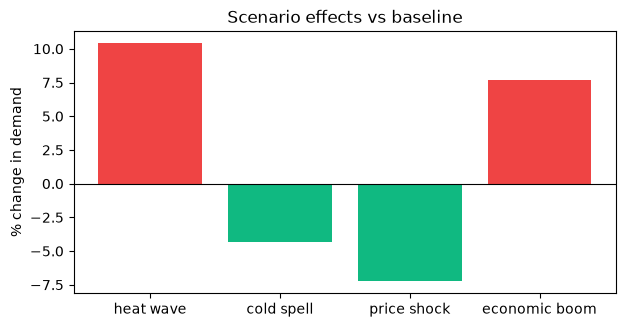

In [4]:
pct = {n: results[n]['percentage_change'] for n in SCENARIOS}
plt.figure(figsize=(7, 3.4))
plt.bar([n.replace('_', ' ') for n in pct], list(pct.values()), color=['#ef4444' if v > 0 else '#10b981' for v in pct.values()])
plt.axhline(0, color='black', lw=0.8); plt.ylabel('% change in demand'); plt.title('Scenario effects vs baseline'); plt.show()

## Step 3: A scenario across the day
Averages hide *when* demand rises. Here we use a normal Wednesday in June and compare the 24-hour curve with and without a heat wave.

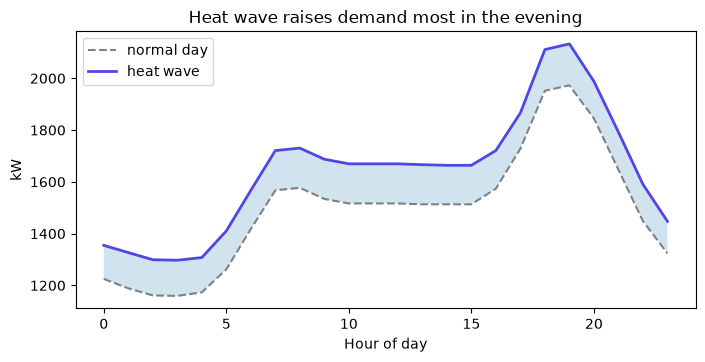

Peak: normal 1973 kW at 19:00, heat wave 2133 kW at 19:00


In [5]:
typical = json.load(open(MODELS / 'reference.json'))['typical']
day = pd.DataFrame([{**typical, 'Hour of Day': h} for h in range(24)])[FEATURES]
normal_curve = model.predict(day)
hot_curve = model.predict(apply_scenario(day, 'heat_wave')[FEATURES])

plt.figure(figsize=(8, 3.6))
plt.plot(range(24), normal_curve, '--', color='grey', label='normal day')
plt.plot(range(24), hot_curve, lw=2, color='#4f46e5', label='heat wave')
plt.fill_between(range(24), normal_curve, hot_curve, alpha=0.2)
plt.xlabel('Hour of day'); plt.ylabel('kW'); plt.title('Heat wave raises demand most in the evening'); plt.legend(); plt.show()
print(f'Peak: normal {normal_curve.max():.0f} kW at {normal_curve.argmax()}:00, heat wave {hot_curve.max():.0f} kW at {hot_curve.argmax()}:00')

## Step 4: Which inputs matter most? (one-at-a-time sensitivity)
For a normal day at the evening peak, move each input from its typical low (5th percentile) to its typical high (95th percentile),
keeping everything else fixed, and see how far demand swings.

In [6]:
ranges = json.load(open(MODELS / 'reference.json'))['ranges']
base_row = {**typical, 'Hour of Day': 19}                            # 7 PM, the evening peak
rows = []
for feature in ['Temperature (°C)', 'Humidity (%)', 'Electricity Price (LKR/kWh)', 'GDP (LKR)', 'Per Capita Energy Use (kWh)', 'Rainfall (mm)', 'Wind Speed (m/s)']:
    lo = model.predict(pd.DataFrame([{**base_row, feature: ranges[feature]['p5']}])[FEATURES])[0]
    hi = model.predict(pd.DataFrame([{**base_row, feature: ranges[feature]['p95']}])[FEATURES])[0]
    rows.append((feature, lo, hi, abs(hi - lo)))
sens = pd.DataFrame(rows, columns=['feature', 'demand at low', 'demand at high', 'swing (kW)']).sort_values('swing (kW)', ascending=False)
sens.round(0)

,feature,demand at low,demand at high,swing (kW)
2,Electricity Price (LKR/kWh),2084.0,1888.0,196.0
0,Temperature (°C),1902.0,2072.0,170.0
3,GDP (LKR),1920.0,2023.0,103.0
5,Rainfall (mm),1999.0,1908.0,91.0
4,Per Capita Energy Use (kWh),1936.0,2014.0,78.0
6,Wind Speed (m/s),1994.0,1952.0,42.0
1,Humidity (%),1968.0,1973.0,6.0


## Step 5: Save the results for the API

In [7]:
payload = dict(metadata=dict(baseline_samples=1000, model_type=meta['model_type'], features_count=len(FEATURES),
                             baseline_demand=baseline, model_performance=meta['model_performance']), scenarios=results)
json.dump(payload, open(OUTPUTS / 'scenario_results.json', 'w'), indent=2)
print('Saved scenario_results.json')

Saved scenario_results.json


## Summary
* A heat wave raises demand (air-conditioning); a price shock lowers it; an economic boom raises it; a cold spell lowers it.
* The evening hours are where scenario effects matter most for the grid.
* These what-ifs reuse the same deployed model, so they stay consistent with the Predict tab and the Grid Decision Lab.